## PROJETO SEMANTIX

In [41]:
# Biblioteca para manipulação de dados
import pandas as pd
import numpy as np

# Biblioteca para vizualização de dados
import matplotlib.pyplot as plt 
import seaborn as sns

# Bibliotecas para pré-processamento e divisão de dados
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

# Bibliotrecas para os modelos de machine learning
import xgboost as XGBRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score, cross_val_predict


# Bibliotecas para métricas de avaliação
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

In [42]:
!pip install xgboost

In [7]:
# Carregar a base
df = pd.read_csv(
    "BASE_CONSUMO_ENERGIA_BRASIL_2025_2026.csv"
)

# Converter coluna de data
df["din_instante"] = pd.to_datetime(df["din_instante"])

# Visualizar os dados
display(df.head())

# Conferir dimensões
print(df.shape)

# Informações da base
df.info()


,din_instante,data,hora,dia_semana,mes,carga_nordeste_mw,carga_norte_mw,carga_sudeste_centro_oeste_mw,carga_sul_mw,carga_total_brasil_mw
0,2025-01-01 00:00:00,2025-01-01,0,2,1,12251.182,7097.751,35374.033,10554.603,65277.569
1,2025-01-01 01:00:00,2025-01-01,1,2,1,12460.162,7053.337,35373.185,10828.138,65714.822
2,2025-01-01 02:00:00,2025-01-01,2,2,1,12588.628,7244.130,35141.831,10605.041,65579.630
3,2025-01-01 03:00:00,2025-01-01,3,2,1,12604.346,7255.306,34470.608,10260.226,64590.486
4,2025-01-01 04:00:00,2025-01-01,4,2,1,12596.084,7232.931,33814.527,9971.459,63615.001


(16320, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16320 entries, 0 to 16319
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   din_instante                   16320 non-null  datetime64[ns]
 1   data                           16320 non-null  object        
 2   hora                           16320 non-null  int64         
 3   dia_semana                     16320 non-null  int64         
 4   mes                            16320 non-null  int64         
 5   carga_nordeste_mw              16320 non-null  float64       
 6   carga_norte_mw                 16320 non-null  float64       
 7   carga_sudeste_centro_oeste_mw  16320 non-null  float64       
 8   carga_sul_mw                   16320 non-null  float64       
 9   carga_total_brasil_mw          16320 non-null  float64       
dtypes: datetime64[ns](1), float64(5), int64(3), object(1)
memory usage: 1.

In [ ]:
# Os dados estão de acordo para que possam ser utilizados nos modelos preditivos.

In [8]:
df.isnull().sum()

din_instante                     0
data                             0
hora                             0
dia_semana                       0
mes                              0
carga_nordeste_mw                0
carga_norte_mw                   0
carga_sudeste_centro_oeste_mw    0
carga_sul_mw                     0
carga_total_brasil_mw            0
dtype: int64

In [ ]:
# Não há dados nulos, o que facilita a etapa de pré-processamento.

## variaveis 

Data e horário : data contabilizada a cada 1 hora

Hora do dia : horario de consumo

Dia da semana : dia de consumo

Mês : mes de consumo

Demanda do Norte : consumo de energia no norte

Demanda do Nordeste : consumo no nordeste

Demanda do Sudeste/Centro-Oeste : consumo no sudeste/centro-oeste

Demanda do Sul : consumo na região sul

Demanda total do Brasil : variável alvo

In [9]:
# Garantir que a coluna de data esteja no formato datetime
df["din_instante"] = pd.to_datetime(df["din_instante"])

# Organizar os registros cronologicamente
df = df.sort_values("din_instante").reset_index(drop=True)

# Criar lista com as variáveis regionais
colunas_regioes = [
    "carga_norte_mw",
    "carga_nordeste_mw",
    "carga_sudeste_centro_oeste_mw",
    "carga_sul_mw"
]

# Verificar duplicidades de horários
print("Horários duplicados:",
      df["din_instante"].duplicated().sum())

# Verificar intervalos entre registros
print("\nIntervalos entre registros:")
print(df["din_instante"].diff().value_counts().head())

Horários duplicados: 0

Intervalos entre registros:
din_instante
0 days 01:00:00    16319
Name: count, dtype: int64


In [ ]:
# Fizemos uma organização quanto a variável de data/hora, acompanhamos horários duplicados, além de uma criação de variáveis regionais para melhor vizualização na tabela e nos modelos. 

## Análise Exploratória de Dados : Consumo Por Regiões

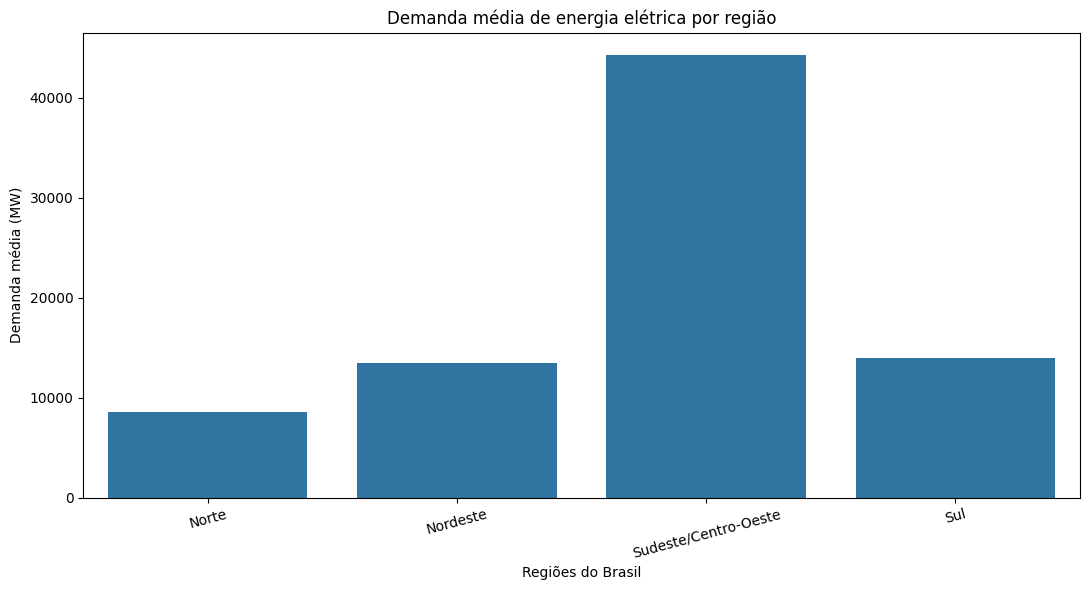

In [10]:
media_regional = df[colunas_regioes].mean()

# Organizar os nomes para visualização
media_regional.index = [
    "Norte",
    "Nordeste",
    "Sudeste/Centro-Oeste",
    "Sul"
]

plt.figure(figsize=(11, 6))

sns.barplot(
    x=media_regional.index,
    y=media_regional.values
)

plt.title("Demanda média de energia elétrica por região")
plt.xlabel("Regiões do Brasil")
plt.ylabel("Demanda média (MW)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [48]:
# Podemos notar claramente a discrepancia quanto ao consumo de energia na região Sudeste/Centro-Oeste, que somam mais de 40 mil MW.
# Outras regiões como Sul e Nordeste somam 15000 MW cada, enquanto que o Norte tem consumo médio abaixo dos 10000 MW.
# Esses dados são esperados, uma vez que em densidade populacional, as regiões Sudeste e Centro-oeste são compostas por grandes estados como são Paulo, Mato Grosso, Rio de Janeiro e Goias.

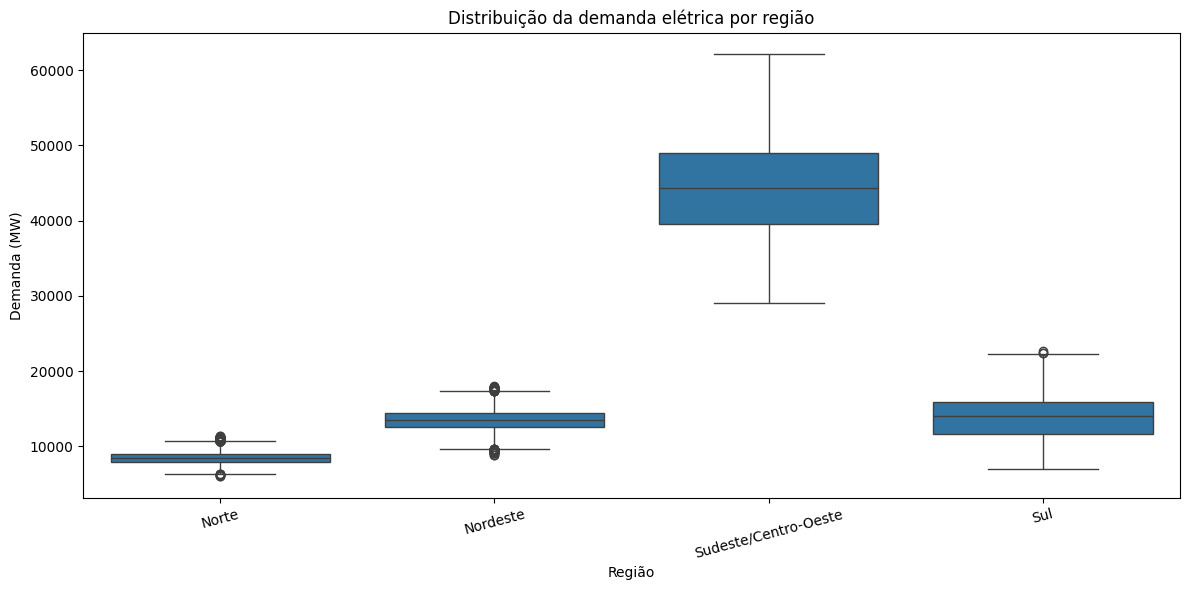

In [11]:
dados_regioes = df[colunas_regioes].melt(
    var_name="Regiao",
    value_name="Demanda_MW"
)

dados_regioes["Regiao"] = dados_regioes["Regiao"].replace({
    "carga_norte_mw": "Norte",
    "carga_nordeste_mw": "Nordeste",
    "carga_sudeste_centro_oeste_mw": "Sudeste/Centro-Oeste",
    "carga_sul_mw": "Sul"
})

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=dados_regioes,
    x="Regiao",
    y="Demanda_MW"
)

plt.title("Distribuição da demanda elétrica por região")
plt.xlabel("Região")
plt.ylabel("Demanda (MW)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [49]:
# No gráfico de BoxPlot foi identificado possíveis outliers nas regiões Norte, Nordeste e sul, a excessão da região Sudeste/Centro-Oeste.
# Faremos uma análise para ver a representatividade dos outliers nos dados como um todo, e também descobrir se de fato são outliers ou se esses possíveis outliers não estão atrelados a condições adversas, tais como
# Periodo do ano e feriados.

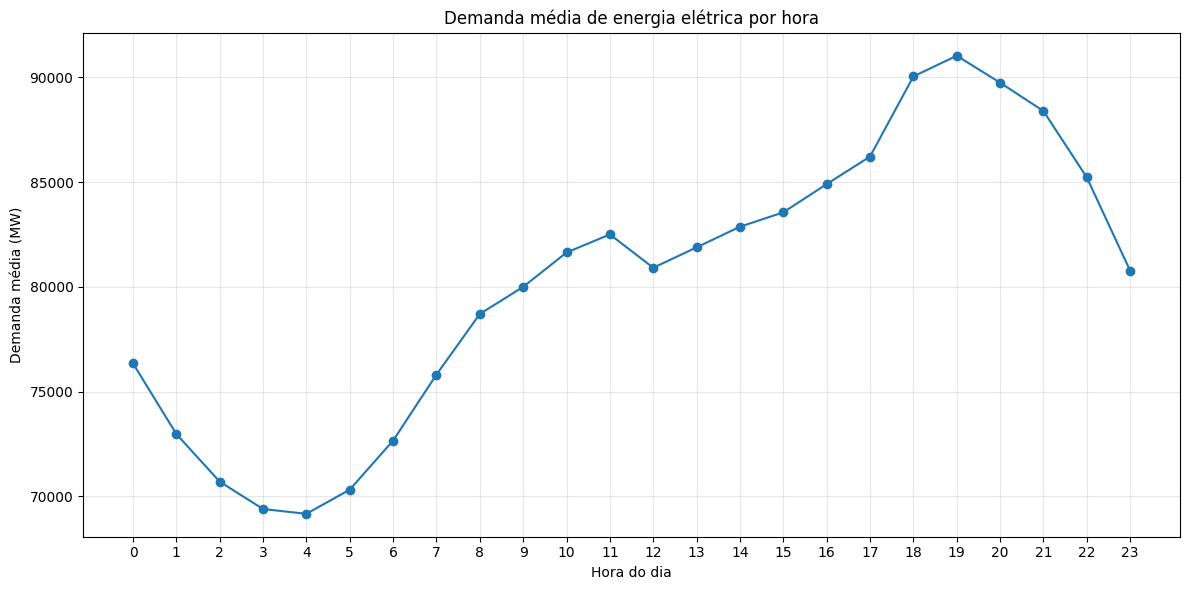

In [12]:
consumo_horario = df.groupby("hora")[
    "carga_total_brasil_mw"
].mean()

plt.figure(figsize=(12, 6))

plt.plot(
    consumo_horario.index,
    consumo_horario.values,
    marker="o"
)

plt.title("Demanda média de energia elétrica por hora")
plt.xlabel("Hora do dia")
plt.ylabel("Demanda média (MW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# O gráfico em linha demonstra a taxa de elevação e queda no consumo de eneria em media durante o dia.
# Podemos ver que a queda é ascentuada entre meia noite às 4 da manhã, onde a população esta dormindo, atingindo minimas abaixo dos 70000 MW
# A partir das 4 às 11 da manhã, onde a atividade econômica acontece, o consumo sobe acima dos 80000 MW.
# O pico de consumo é atingido as 19 horas da tarde com media passando da casa dos 90 mil MW, após esse horário começa a haver queda vertiginosa.

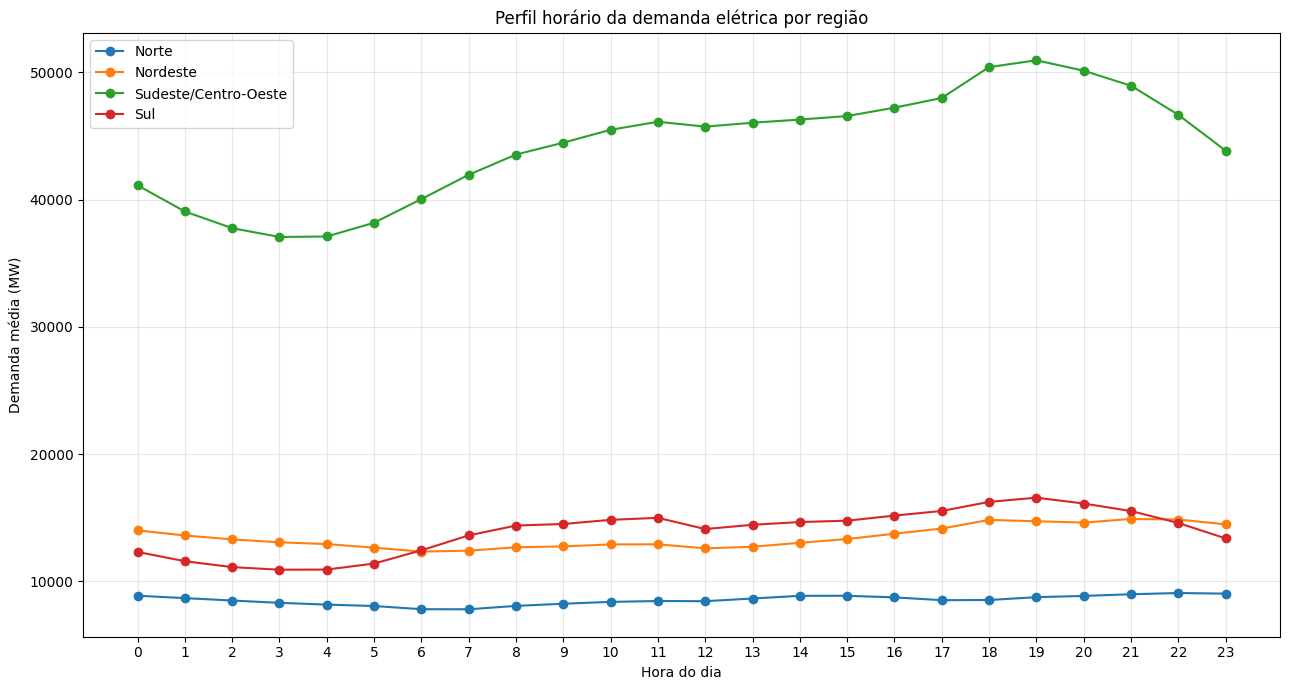

In [13]:
perfil_horario = df.groupby("hora")[colunas_regioes].mean()

nomes_regioes = {
    "carga_norte_mw": "Norte",
    "carga_nordeste_mw": "Nordeste",
    "carga_sudeste_centro_oeste_mw": "Sudeste/Centro-Oeste",
    "carga_sul_mw": "Sul"
}

perfil_horario = perfil_horario.rename(columns=nomes_regioes)

plt.figure(figsize=(13, 7))

for regiao in perfil_horario.columns:
    plt.plot(
        perfil_horario.index,
        perfil_horario[regiao],
        marker="o",
        label=regiao
    )

plt.title("Perfil horário da demanda elétrica por região")
plt.xlabel("Hora do dia")
plt.ylabel("Demanda média (MW)")
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# O gráfico em linha mostra o consumo por hora do dia distribuido por regiões, o que ajuda a identificar as regiões que costuma puxar a média para cima.
# A Região sul e Nordeste tendem a ter o mesmo consumo de energia ao longo do dia, não passando dos 20 mil MW, enquanto que a região norte mantem consumo a baixo dos 10 mil MW.
# Podemos ver que grande parte da ,edia de consumo é puxada pela região suldeste e centro-oeste, onde em baixos níves de consumo tendem a estar abaixo dos 40 mil MW, enquanto o pico ultrapassa os 50 mil

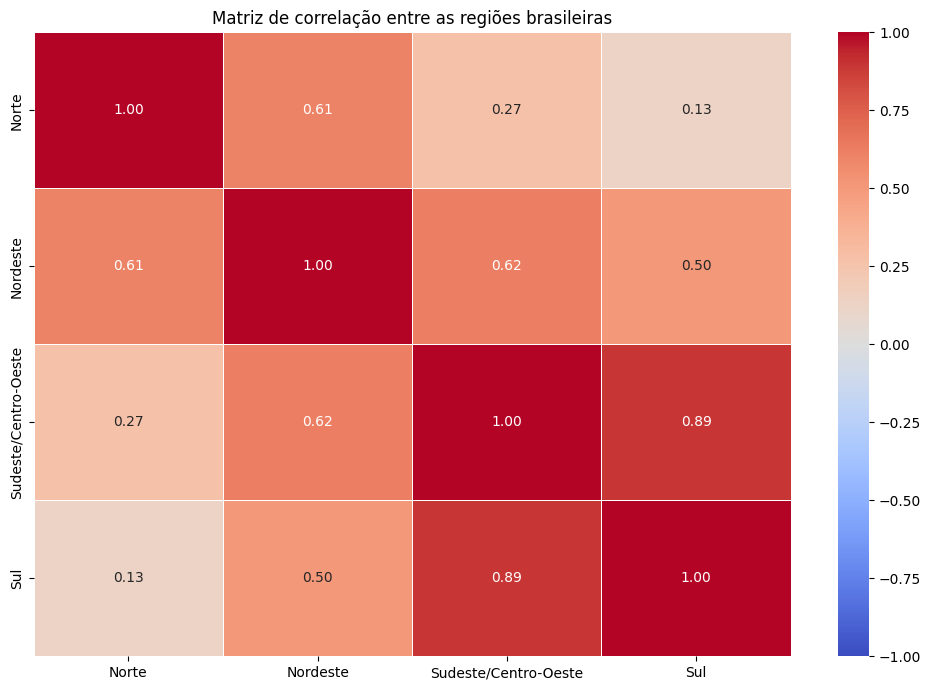

In [14]:
# Selecionar somente as cargas regionais
correlacao = df[colunas_regioes].corr()

# Renomear as variáveis
correlacao = correlacao.rename(
    index=nomes_regioes,
    columns=nomes_regioes
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlação entre as regiões brasileiras")

plt.tight_layout()
plt.show()

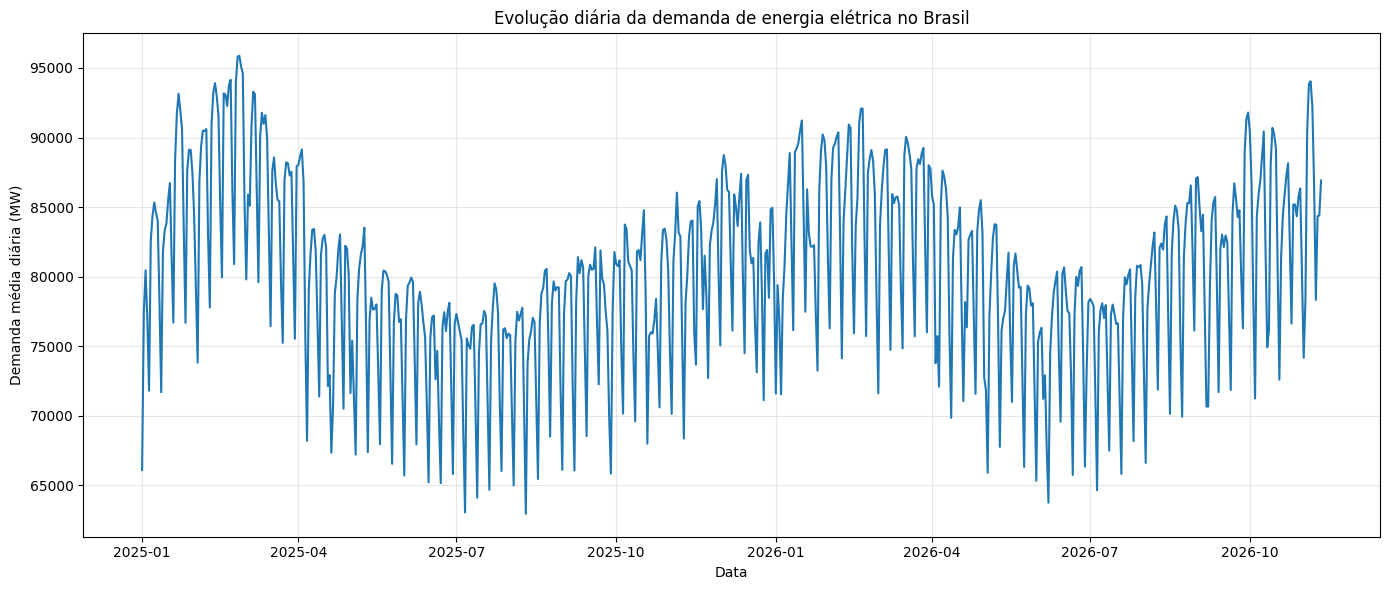

In [15]:
demanda_diaria = df.set_index("din_instante")[
    "carga_total_brasil_mw"
].resample("D").mean()

plt.figure(figsize=(14, 6))

plt.plot(demanda_diaria.index, demanda_diaria.values)

plt.title("Evolução diária da demanda de energia elétrica no Brasil")
plt.xlabel("Data")
plt.ylabel("Demanda média diária (MW)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# O gráfico mostra o consumo nacional ao longo de 1 ano, podemos identificar que existe um padrão de consumo ao longo dos periodos do ano.
# no mes 7 de 2025 é um reflexo do mesmo mes do ano seguinte, o mesmo não se aplica ao pico do mes 1 de 2025 com o mesmo mes de 2026, onde, onde ouve um consumo mais centuado em 2025

## Análise Exploratória de Dados : Demanda Média Por Hora

In [16]:
# Calcular a média de demanda para cada hora do dia
consumo_horario = df.groupby("hora")[
    "carga_total_brasil_mw"
].mean()

# Exibir os resultados
display(consumo_horario.round(2))

hora
0     76342.73
1     72969.46
2     70695.64
3     69388.89
4     69160.06
5     70316.52
6     72659.52
7     75811.50
8     78705.74
9     80000.39
10    81641.20
11    82503.78
12    80911.15
13    81886.79
14    82872.08
15    83558.79
16    84907.78
17    86221.93
18    90049.66
19    91038.46
20    89751.48
21    88397.04
22    85228.58
23    80771.21
Name: carga_total_brasil_mw, dtype: float64

In [ ]:
# O consumo nacional médio por hora ficar mais evidente dessa forma, apontando justamente sobre as horas em que a população esta em casa, dormindo e trabalhando, são os momentos em que há maior oxilação gasto com eletricidade. 

In [17]:
# Horário de maior demanda
horario_pico = consumo_horario.idxmax()
demanda_maxima = consumo_horario.max()

# Horário de menor demanda
horario_minimo = consumo_horario.idxmin()
demanda_minima = consumo_horario.min()

print(f"Horário de maior demanda: {horario_pico}h")
print(f"Demanda máxima média: {demanda_maxima:.2f} MW")

print("-" * 40)

print(f"Horário de menor demanda: {horario_minimo}h")
print(f"Demanda mínima média: {demanda_minima:.2f} MW")

Horário de maior demanda: 19h
Demanda máxima média: 91038.46 MW
----------------------------------------
Horário de menor demanda: 4h
Demanda mínima média: 69160.06 MW


In [ ]:
# Fica evidente oque já foi observado quanto ao alto nível de consumo e  o baixo nível de consumo.

## Análise Exploratória de Dados : Demanda Por da Semana

In [18]:
# Calcular a demanda média por dia da semana
consumo_dia_semana = df.groupby("dia_semana")[
    "carga_total_brasil_mw"
].mean()

# Identificar os dias da semana
consumo_dia_semana.index = [
    "Segunda-feira",
    "Terça-feira",
    "Quarta-feira",
    "Quinta-feira",
    "Sexta-feira",
    "Sábado",
    "Domingo"
]

# Exibir resultados
display(consumo_dia_semana.round(2))

Segunda-feira    81435.23
Terça-feira      83156.19
Quarta-feira     83198.91
Quinta-feira     82999.24
Sexta-feira      82930.84
Sábado           76916.15
Domingo          71021.82
Name: carga_total_brasil_mw, dtype: float64

In [ ]:
# Avaliamos o consumo ao longo da semana para tentar identificar padrões de consumo, podemos notar que o consumo é parecido de segunda a sexta-feira, se mantendo na casa dos 80 mil MW.
# Porém durante os finais de semana, o consumo fica a baixo dos 80 mil MW, podemos interpretar que grandes empresas se encontram fechados aos finais de semana, a produtividade economica do pais desacelera devido as folgas de funcioários.

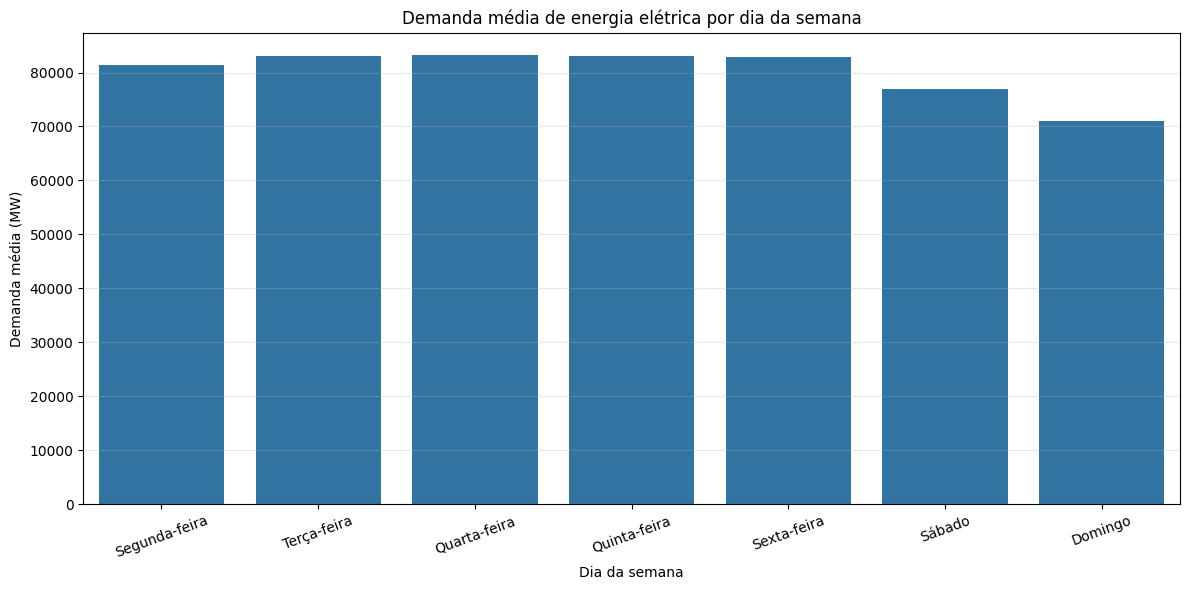

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=consumo_dia_semana.index,
    y=consumo_dia_semana.values
)

plt.title("Demanda média de energia elétrica por dia da semana")
plt.xlabel("Dia da semana")
plt.ylabel("Demanda média (MW)")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# O gráfico em barras deixa evidente que o final de semana apresenta queda relativa se comparada aos demias dias da semana, o que representa economia de mais de 5 mil MW.

In [20]:
# Dia de maior demanda
dia_maior_demanda = consumo_dia_semana.idxmax()
maior_demanda = consumo_dia_semana.max()

# Dia de menor demanda
dia_menor_demanda = consumo_dia_semana.idxmin()
menor_demanda = consumo_dia_semana.min()

print(f"Dia de maior demanda: {dia_maior_demanda}")
print(f"Demanda média: {maior_demanda:.2f} MW")

print("-" * 40)

print(f"Dia de menor demanda: {dia_menor_demanda}")
print(f"Demanda média: {menor_demanda:.2f} MW")

Dia de maior demanda: Quarta-feira
Demanda média: 83198.91 MW
----------------------------------------
Dia de menor demanda: Domingo
Demanda média: 71021.82 MW


In [ ]:
# Assim como identificamos os horários de maior e baixo consumo, realizamos a mesma métrica para entender os dias com maior e menor consumo.
# No domingo podemos considerar que muitos estabelecimentos fecham cedo, além da atividade produtiva nacional cai com parte da população estando em casa.

## Análise Exploratória de Dados : Demanda Mensal


In [21]:
# Agrupar os dados por mês e calcular a demanda média
consumo_mensal = df.groupby("mes")[
    "carga_total_brasil_mw"
].mean()

# Identificar os nomes dos meses
nomes_meses = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março",
    4: "Abril",
    5: "Maio",
    6: "Junho",
    7: "Julho",
    8: "Agosto",
    9: "Setembro",
    10: "Outubro",
    11: "Novembro",
    12: "Dezembro"
}

consumo_mensal.index = consumo_mensal.index.map(nomes_meses)

display(consumo_mensal.round(2))

mes
Janeiro      83157.84
Fevereiro    87445.62
Março        85310.93
Abril        80067.42
Maio         76359.65
Junho        74986.30
Julho        75140.16
Agosto       77465.65
Setembro     79712.51
Outubro      81284.74
Novembro     81677.18
Dezembro     82315.87
Name: carga_total_brasil_mw, dtype: float64

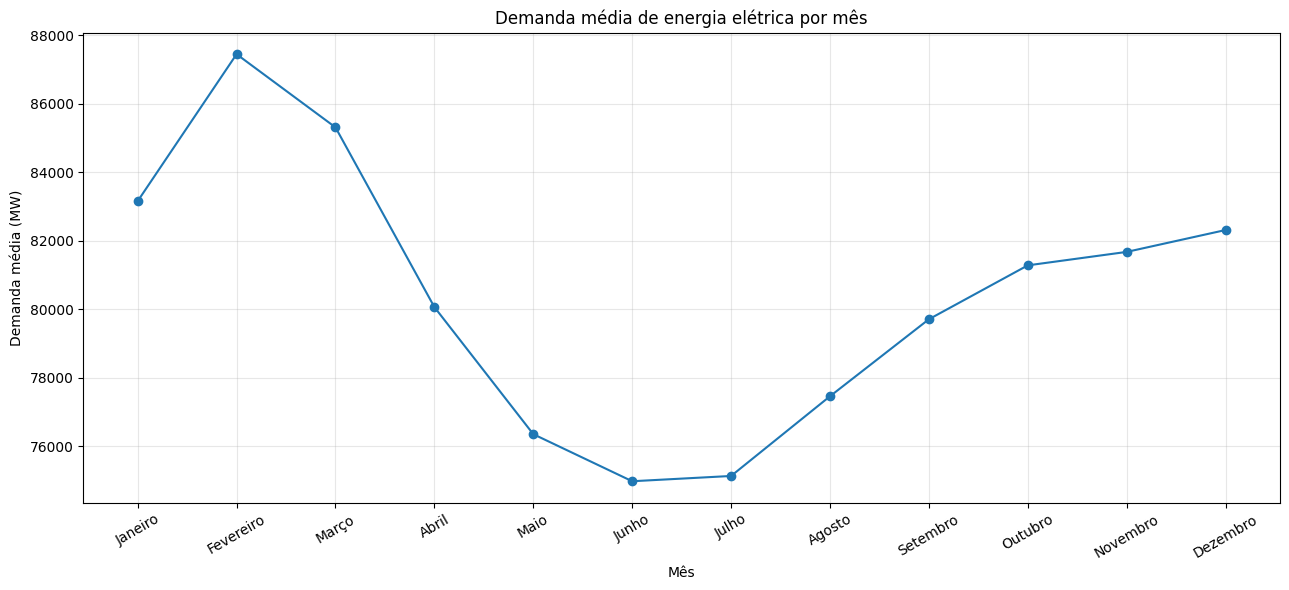

In [22]:
plt.figure(figsize=(13, 6))

plt.plot(
    consumo_mensal.index,
    consumo_mensal.values,
    marker="o"
)

plt.title("Demanda média de energia elétrica por mês")
plt.xlabel("Mês")
plt.ylabel("Demanda média (MW)")

plt.xticks(rotation=30)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
mes_maior_demanda = consumo_mensal.idxmax()
maior_demanda = consumo_mensal.max()

mes_menor_demanda = consumo_mensal.idxmin()
menor_demanda = consumo_mensal.min()

print(f"Mês de maior demanda: {mes_maior_demanda}")
print(f"Demanda média: {maior_demanda:.2f} MW")

print("-" * 40)

print(f"Mês de menor demanda: {mes_menor_demanda}")
print(f"Demanda média: {menor_demanda:.2f} MW")

Mês de maior demanda: Fevereiro
Demanda média: 87445.62 MW
----------------------------------------
Mês de menor demanda: Junho
Demanda média: 74986.30 MW


In [ ]:
# Podemos acompanhar a curva de queda e crescimento do consumo de energia ao longo do ano.
# o pico de consumo provem entre os meses de janeiro e fevereiro, após esses dois meses, o consumo de energia tende a diminuir até a metade do ano.
# de junho a dezembro, o aumento é gradativo, onde dezembro fecha com media de 83 mil MW.

## Análise Exploratória de Dados : Distribuição da Demanda Nacional

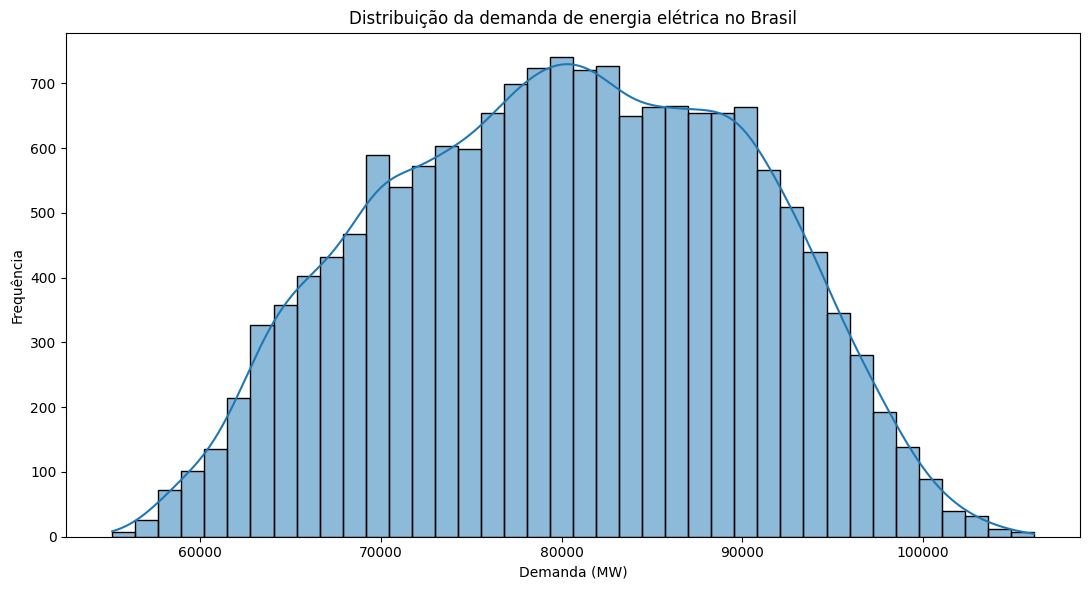

In [24]:
plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x="carga_total_brasil_mw",
    bins=40,
    kde=True
)

plt.title("Distribuição da demanda de energia elétrica no Brasil")
plt.xlabel("Demanda (MW)")
plt.ylabel("Frequência")

plt.tight_layout()
plt.show()

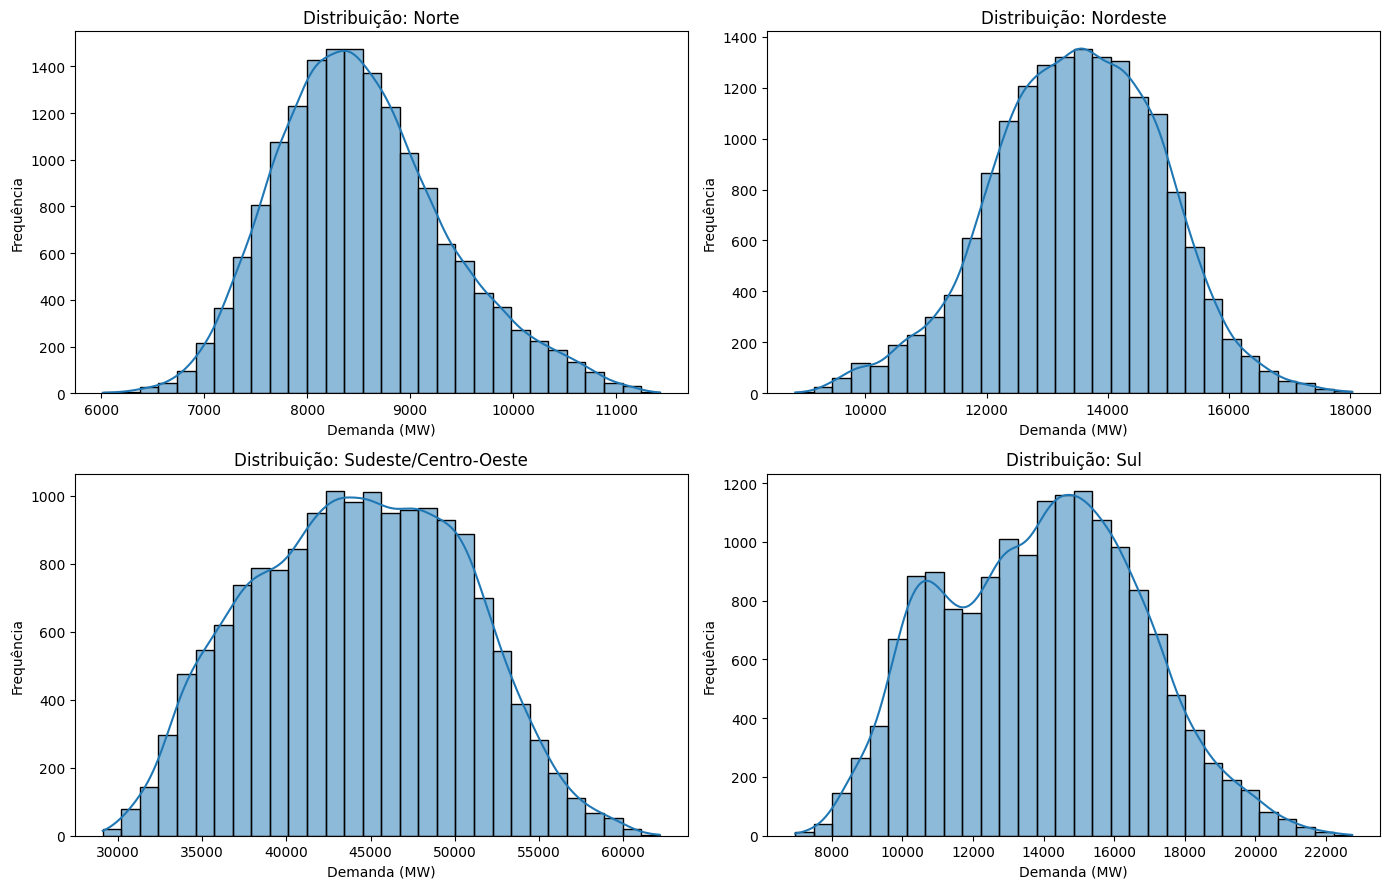

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for coluna, ax in zip(colunas_regioes, axes.flatten()):
    sns.histplot(
        data=df,
        x=coluna,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribuição: {nomes_regioes[coluna]}")
    ax.set_xlabel("Demanda (MW)")
    ax.set_ylabel("Frequência")

plt.tight_layout()
plt.show()

## Análise Exploratória de Dados : Identificando Possíveis Outliers

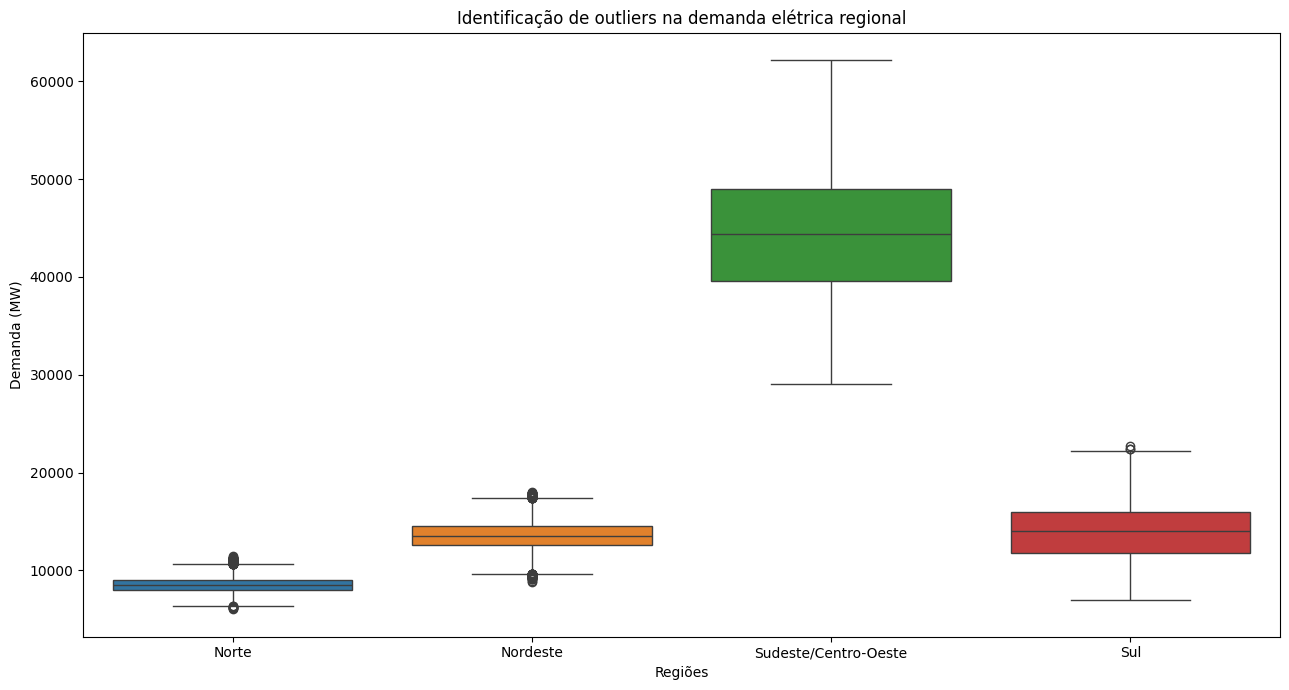

In [26]:
plt.figure(figsize=(13, 7))

dados_boxplot = df[colunas_regioes].rename(
    columns=nomes_regioes
)

sns.boxplot(data=dados_boxplot)

plt.title("Identificação de outliers na demanda elétrica regional")
plt.xlabel("Regiões")
plt.ylabel("Demanda (MW)")

plt.tight_layout()
plt.show()

In [ ]:
# O BoxPlot mostra os outliers que citamos no começo da análise, vamos analisar e tratar se necessário.

for coluna in colunas_regioes:

    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    print(f"\nRegião: {nomes_regioes[coluna]}")
    print(f"Quantidade de outliers: {len(outliers)}")
    print(f"Limite inferior: {limite_inferior:.2f} MW")
    print(f"Limite superior: {limite_superior:.2f} MW")

In [27]:
for coluna in colunas_regioes:

    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    print(f"\nRegião: {nomes_regioes[coluna]}")
    print("Primeiros registros identificados:")
    print(outliers[["din_instante", coluna]].head())


Região: Norte
Primeiros registros identificados:
           din_instante  carga_norte_mw
439 2025-01-19 07:00:00        6225.728
440 2025-01-19 08:00:00        6150.419
441 2025-01-19 09:00:00        6113.244
442 2025-01-19 10:00:00        6186.266
443 2025-01-19 11:00:00        6306.261

Região: Nordeste
Primeiros registros identificados:
            din_instante  carga_nordeste_mw
4137 2025-06-22 09:00:00           9621.279
4304 2025-06-29 08:00:00           9616.592
4305 2025-06-29 09:00:00           9585.698
4306 2025-06-29 10:00:00           9510.704
4307 2025-06-29 11:00:00           9544.072

Região: Sudeste/Centro-Oeste
Primeiros registros identificados:
Empty DataFrame
Columns: [din_instante, carga_sudeste_centro_oeste_mw]
Index: []

Região: Sul
Primeiros registros identificados:
            din_instante  carga_sul_mw
998  2025-02-11 14:00:00     22737.443
999  2025-02-11 15:00:00     22386.006
1334 2025-02-25 14:00:00     22431.881


In [ ]:
# Plotamos o dia em que ocorreu o outlier para ver se há padrões dentro desses "erros", notamos que no norte, o consumo está abaixo da media, entre outras regiões.

## Análise da Distribuição dos outliers

                   Q1, Q2 e IQR

Q1: primeiro quartil, correspondente a 25% da distribuição.

Q3: terceiro quartil, correspondente a 75% da distribuição.

IQR: diferença entre Q3 e Q1

In [28]:
# Garantir que a coluna de data esteja no formato datetime
df["din_instante"] = pd.to_datetime(df["din_instante"])

registros_outliers = []

for coluna in colunas_regioes:

    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    mascara = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    )

    temporario = df.loc[mascara, ["din_instante", coluna]].copy()

    temporario = temporario.rename(
        columns={coluna: "carga_mw"}
    )

    temporario["regiao"] = nomes_regioes[coluna]

    temporario["tipo_outlier"] = np.where(
        temporario["carga_mw"] < limite_inferior,
        "Abaixo do limite",
        "Acima do limite"
    )

    registros_outliers.append(temporario)

# Consolidar todos os registros
outliers_df = pd.concat(
    registros_outliers,
    ignore_index=True
)

outliers_df.head(10)


,din_instante,carga_mw,regiao,tipo_outlier
0,2025-01-19 07:00:00,6225.728,Norte,Abaixo do limite
1,2025-01-19 08:00:00,6150.419,Norte,Abaixo do limite
2,2025-01-19 09:00:00,6113.244,Norte,Abaixo do limite
3,2025-01-19 10:00:00,6186.266,Norte,Abaixo do limite
4,2025-01-19 11:00:00,6306.261,Norte,Abaixo do limite
5,2025-02-16 09:00:00,6299.037,Norte,Abaixo do limite
6,2025-12-25 15:00:00,6015.876,Norte,Abaixo do limite
7,2026-04-03 09:00:00,6302.307,Norte,Abaixo do limite
8,2026-08-11 14:00:00,10753.647,Norte,Acima do limite
9,2026-08-12 14:00:00,10676.310,Norte,Acima do limite


In [ ]:
# Podemos tirar insights valiosos dos dados apresentados, vemos que o consumo atípico ficou abaixo do limite estatístico estabelicido pelo IQR, tendo ocorrido no mesmo dia (19-01-2025)
# Podemos levar em consideração o primeiro mes do ano, possivelmente a população poderia ter viajado para as demais regiões, ou talvez tivessemos uma queda de energia na região, oque justificaria essa queda de cosnumo no dia específico.
# No mes 8 tivemos dois dias de consumo elevado de energia, estando acima do limite estatístico estabelecido pelo IQR.

In [29]:
outliers_df["mes"] = outliers_df["din_instante"].dt.month

distribuicao_mensal = (
    outliers_df.groupby(["regiao", "mes"])
    .size()
    .unstack(fill_value=0)
)

distribuicao_mensal


mes,1,2,3,4,5,6,7,8,9,10,11,12
regiao,,,,,,,,,,,,
Nordeste,0,0,1,7,12,15,18,6,0,3,30,3
Norte,5,1,0,1,0,0,0,21,82,73,10,1
Sul,0,3,0,0,0,0,0,0,0,0,0,0


In [30]:
outliers_df["hora"] = outliers_df["din_instante"].dt.hour

distribuicao_horaria = (
    outliers_df.groupby(["regiao", "hora"])
    .size()
    .unstack(fill_value=0)
)

distribuicao_horaria


hora,0,7,8,9,10,11,12,13,14,15,16,18,19,20,21,22,23
regiao,,,,,,,,,,,,,,,,,
Nordeste,0,0,4,16,11,8,8,10,7,1,4,3,2,3,7,8,3
Norte,1,1,1,3,2,7,13,38,52,35,4,0,0,0,6,20,11
Sul,0,0,0,0,0,0,0,0,2,1,0,0,0,0,0,0,0


In [31]:
# Resumo final dos outliers

print("OUTLIERS POR REGIÃO:")
print(outliers_df["regiao"].value_counts())

print("\nOUTLIERS POR TIPO:")
print(outliers_df["tipo_outlier"].value_counts())

print("\nOUTLIERS POR MÊS:")
print(outliers_df.groupby("mes").size())

print("\nOUTLIERS POR HORÁRIO:")
print(outliers_df.groupby("hora").size())

print("\nTOTAL DE OUTLIERS:")
print(len(outliers_df))


OUTLIERS POR REGIÃO:
regiao
Norte       194
Nordeste     95
Sul           3
Name: count, dtype: int64

OUTLIERS POR TIPO:
tipo_outlier
Acima do limite     221
Abaixo do limite     71
Name: count, dtype: int64

OUTLIERS POR MÊS:
mes
1      5
2      4
3      1
4      8
5     12
6     15
7     18
8     27
9     82
10    76
11    40
12     4
dtype: int64

OUTLIERS POR HORÁRIO:
hora
0      1
7      1
8      5
9     19
10    13
11    15
12    21
13    48
14    61
15    37
16     8
18     3
19     2
20     3
21    13
22    28
23    14
dtype: int64

TOTAL DE OUTLIERS:
292


In [ ]:
# Após uma análise minuciosa e considerar os dados como um todo, a representatividade dos outliers são baixa se comparar a um todo, por tanto decidi manter os outliers pois representa uma fatia minima dos dados.

In [32]:
# Organizar os dados cronologicamente
df["din_instante"] = pd.to_datetime(df["din_instante"])

df = df.sort_values("din_instante").reset_index(drop=True)

# Verificar registros duplicados
print("Datas duplicadas:",
      df["din_instante"].duplicated().sum())

# Verificar intervalos entre registros
intervalos = df["din_instante"].diff()

print("\nIntervalos diferentes de 1 hora:")
print((intervalos.dropna() != pd.Timedelta(hours=1)).sum())

# Verificar período da base
print("\nPrimeiro registro:", df["din_instante"].min())
print("Último registro:", df["din_instante"].max())

print("\nDimensões da base:", df.shape)

Datas duplicadas: 0

Intervalos diferentes de 1 hora:
0

Primeiro registro: 2025-01-01 00:00:00
Último registro: 2026-11-11 23:00:00

Dimensões da base: (16320, 10)


In [ ]:
# Reagrupar os dados cronologicamente, para acompanhar o consumo pelo histórico, não pelo volume ou região.

## Criação de uma Base de Dados Independente, Para cada Região


In [33]:
# Organizar a base cronologicamente
df = df.sort_values("din_instante").copy()

# Criar função para engenharia de atributos
def criar_variaveis(dados, coluna):

    base = dados[["din_instante", coluna]].copy()

    base = base.rename(columns={coluna: "demanda_mw"})

    # Variáveis temporais
    base["hora"] = base["din_instante"].dt.hour
    base["dia_semana"] = base["din_instante"].dt.dayofweek
    base["mes"] = base["din_instante"].dt.month
    base["dia_ano"] = base["din_instante"].dt.dayofyear
    base["fim_de_semana"] = (
        base["dia_semana"] >= 5
    ).astype(int)

    # Variáveis cíclicas
    base["hora_sin"] = np.sin(2 * np.pi * base["hora"] / 24)
    base["hora_cos"] = np.cos(2 * np.pi * base["hora"] / 24)

    base["mes_sin"] = np.sin(2 * np.pi * base["mes"] / 12)
    base["mes_cos"] = np.cos(2 * np.pi * base["mes"] / 12)

    # Variáveis de demanda passada
    base["lag_1"] = base["demanda_mw"].shift(1)
    base["lag_24"] = base["demanda_mw"].shift(24)
    base["lag_168"] = base["demanda_mw"].shift(168)

    # Médias móveis sem utilizar dados futuros
    base["media_24h"] = (
        base["demanda_mw"].shift(1)
        .rolling(window=24).mean()
    )

    base["media_168h"] = (
        base["demanda_mw"].shift(1)
        .rolling(window=168).mean()
    )

    return base.dropna().reset_index(drop=True)


# Criar uma base para cada região
bases_regioes = {}

for coluna in colunas_regioes:

    nome = nomes_regioes[coluna]

    bases_regioes[nome] = criar_variaveis(df, coluna)

    print(f"\nRegião: {nome}")
    print("Dimensões:", bases_regioes[nome].shape)




Região: Norte
Dimensões: (16152, 16)

Região: Nordeste
Dimensões: (16152, 16)

Região: Sudeste/Centro-Oeste
Dimensões: (16152, 16)

Região: Sul
Dimensões: (16152, 16)


In [ ]:
# Realizei a separação dos dados por região para que possamos indentificar da melhor forma o comportamento do modelo não nos dados unificados, mais vizualizar os diferentes resultados obtifdos em cada região do Brasil.

## Separação dos Dados em Treino e Teste

In [34]:
# Dicionários para armazenar os conjuntos
X_train = {}
X_test = {}
y_train = {}
y_test = {}

# Colunas que serão utilizadas como variáveis explicativas
features = [
    "hora",
    "dia_semana",
    "mes",
    "dia_ano",
    "fim_de_semana",
    "hora_sin",
    "hora_cos",
    "mes_sin",
    "mes_cos",
    "lag_1",
    "lag_24",
    "lag_168",
    "media_24h",
    "media_168h"
]

# Separação cronológica: 80% treino e 20% teste
for regiao, base in bases_regioes.items():

    indice = int(len(base) * 0.8)

    treino = base.iloc[:indice]
    teste = base.iloc[indice:]

    X_train[regiao] = treino[features]
    X_test[regiao] = teste[features]

    y_train[regiao] = treino["demanda_mw"]
    y_test[regiao] = teste["demanda_mw"]

    print(f"\nRegião: {regiao}")
    print("Treinamento:", X_train[regiao].shape)
    print("Teste:", X_test[regiao].shape)


Região: Norte
Treinamento: (12921, 14)
Teste: (3231, 14)

Região: Nordeste
Treinamento: (12921, 14)
Teste: (3231, 14)

Região: Sudeste/Centro-Oeste
Treinamento: (12921, 14)
Teste: (3231, 14)

Região: Sul
Treinamento: (12921, 14)
Teste: (3231, 14)


 Explicação sobre MAE, RMSE e R2

MAE: representa o erro absoluto médio das previsões. Quanto menor, melhor.
RMSE: penaliza mais fortemente erros de maior magnitude. Quanto menor, melhor.
R²: indica quanto da variabilidade dos dados é explicada pelo modelo. Quanto mais próximo de 1, melhor.

In [35]:
resultados_baseline = []

for regiao in bases_regioes:

    # Previsão utilizando a demanda da hora anterior
    previsao = X_test[regiao]["lag_1"]

    # Valores reais
    real = y_test[regiao]

    # Métricas de avaliação
    mae = mean_absolute_error(real, previsao)

    rmse = np.sqrt(mean_squared_error(real, previsao))

    r2 = r2_score(real, previsao)

    resultados_baseline.append({
        "Região": regiao,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Criar tabela de resultados
resultados_baseline = pd.DataFrame(resultados_baseline)

resultados_baseline

,Região,MAE,RMSE,R2
0,Norte,204.163358,240.254109,0.892530
1,Nordeste,316.492714,398.997759,0.930238
2,Sudeste/Centro-Oeste,1415.136522,1748.657594,0.917056
3,Sul,676.860925,832.575190,0.890786


In [ ]:
# Construi um modelo de referência (BaseLine), utilizando uma tecnica que usa o consumo de energia elétrica da hora anterior (Lag_1) como estimativa para prever a hora seguinte.
# O principal objetivo é usar o baseline como parâmetro inicial de comparação para avaliar os modelo de Machine Learning que serão desenvolvidos a seguir.

## Machine Learning : Regressão Linear

In [36]:
resultados_linear = []
previsoes_linear = {}

for regiao in bases_regioes:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ])

    modelo.fit(X_train[regiao], y_train[regiao])

    previsao = modelo.predict(X_test[regiao])

    previsoes_linear[regiao] = previsao

    real = y_test[regiao]

    mae = mean_absolute_error(real, previsao)
    rmse = np.sqrt(mean_squared_error(real, previsao))
    r2 = r2_score(real, previsao)

    resultados_linear.append({
        "Região": regiao,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

resultados_linear = pd.DataFrame(resultados_linear)

resultados_linear

,Região,MAE,RMSE,R2
0,Norte,136.733444,181.253134,0.938833
1,Nordeste,239.603715,317.333960,0.955872
2,Sudeste/Centro-Oeste,925.882168,1193.944061,0.961333
3,Sul,455.906324,591.581838,0.944861


In [ ]:
# Para os modelos, utilizei o MAE, RMSE e R2 porque queremos prever um valor numérico contínuo, essas métricas, quanto menor o resultado, menor o erro médio das previsões,o R2 quanto maior o valor, melhor, sendo ele a porcentagem referente a capacidade do modelo de explicar a variação dos dados. 
# Sendo assim, a região norte e nordeste teve o melhor resultado geral, pois mesmo tendo o R2 mais baixo que o suldeste/centro-oeste, o modelo é mais preciso, penalizando menos os erros pequenos e grandes, maior equilibrio.

## Machine Learning : Random Forest

In [37]:
resultados_rf = []
previsoes_rf = {}
modelos_rf = {}

for regiao in bases_regioes:

    modelo = RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(X_train[regiao], y_train[regiao])

    previsao = modelo.predict(X_test[regiao])

    previsoes_rf[regiao] = previsao
    modelos_rf[regiao] = modelo

    real = y_test[regiao]

    mae = mean_absolute_error(real, previsao)
    rmse = np.sqrt(mean_squared_error(real, previsao))
    r2 = r2_score(real, previsao)

    resultados_rf.append({
        "Região": regiao,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

resultados_rf = pd.DataFrame(resultados_rf)

resultados_rf

,Região,MAE,RMSE,R2
0,Norte,199.908517,305.181288,0.826594
1,Nordeste,198.283339,285.790100,0.964209
2,Sudeste/Centro-Oeste,388.187483,541.011541,0.992061
3,Sul,190.277511,266.406953,0.988818


In [ ]:
# O modelo teve bons resultados nas regiões Nordeste, Sudeste/Centro-oeste e Sul, nas quais o R2 se manteve acima dos 96%. 
# De uma forma geral, o modelo demonstrou boa capacidade de identificar padrões de consumo.
# Sudeste/Centro-oeste merece um destaque por manter um R2 de99%, embora tenha alto nivel de penalidade a erros em MAE e RMSE.

## Machine Learning : XGBoost

In [46]:
resultados_xgb = []
previsoes_xgb = {}
modelos_xgb = {}

for regiao in bases_regioes:

    modelo = XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(X_train[regiao], y_train[regiao])

    previsao = modelo.predict(X_test[regiao])

    previsoes_xgb[regiao] = previsao
    modelos_xgb[regiao] = modelo

    real = y_test[regiao]

    mae = mean_absolute_error(real, previsao)
    rmse = np.sqrt(mean_squared_error(real, previsao))
    r2 = r2_score(real, previsao)

    resultados_xgb.append({
        "Região": regiao,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

resultados_xgb = pd.DataFrame(resultados_xgb)

resultados_xgb

,Região,MAE,RMSE,R2
0,Norte,239.448705,364.600393,0.752496
1,Nordeste,232.056492,357.045899,0.944137
2,Sudeste/Centro-Oeste,374.127143,525.230857,0.992517
3,Sul,176.063045,246.131122,0.990455


In [ ]:
# O modelo teve bons resultados no Sul, manteve os 99% de R2, sendo que o Sul manteve indices baixos de erros de previsão.
# Em contrapartida o sudeste penaliza pequenos e grandes erros, embora mantenha o R2 acima de 99%
# as demais regiões (Norte e Nordeste) mantem o nivel de penalidade (MAE e RMSE) relativamente baixo, porém o R2 se encontra abaixo de 95%, espicalmente o Norte, que manteve resultado abaixo de 80%.

## Comparando Os Modelos

In [47]:
comparacao_modelos = pd.concat([
    resultados_linear.assign(Modelo='Regressão Linear'),
    resultados_rf.assign(Modelo='Random Forest'),
    resultados_xgb.assign(Modelo='XGBoost')
])

comparacao_modelos = comparacao_modelos[
    ['Região', 'Modelo', 'MAE', 'RMSE', 'R2']
]

comparacao_modelos = comparacao_modelos.sort_values(
    by=['Região', 'MAE']
).reset_index(drop=True)

comparacao_modelos

,Região,Modelo,MAE,RMSE,R2
0,Nordeste,Random Forest,198.283339,285.790100,0.964209
1,Nordeste,XGBoost,232.056492,357.045899,0.944137
2,Nordeste,Regressão Linear,239.603715,317.333960,0.955872
3,Norte,Regressão Linear,136.733444,181.253134,0.938833
4,Norte,Random Forest,199.908517,305.181288,0.826594
5,Norte,XGBoost,239.448705,364.600393,0.752496
6,Sudeste/Centro-Oeste,XGBoost,374.127143,525.230857,0.992517
7,Sudeste/Centro-Oeste,Random Forest,388.187483,541.011541,0.992061
8,Sudeste/Centro-Oeste,Regressão Linear,925.882168,1193.944061,0.961333
9,Sul,XGBoost,176.063045,246.131122,0.990455


In [1]:
# Podemos notar que ao comparar os resultados dos 3 modelos as diferentes regiões, cada modelo se destacou de forma positiva, ao começar pela região:
# Nordeste : O random forest teve excelente desempenho, onde de MAE e RMSE (quanto menor o valor melhor, como foi explicado anteriormente), ficou a baxo dos demais, além do R2 esta acima de 96%
# Norte : A Regressão linear por sua vez se destaca na região norte, tivemos baixo indice se comparado aos demais, e o seu R2 ficou acima de 93%.
# Sudeste/Centro-Oeste : o XGBoost teve valores levemente superiores ao Random Forest, ambos modelos tiveram R2 superiores as 99%.
# Sul : Novamente o XGboost se destaca na região Sul, onde MAE e RMSE estão com niveis baixos se comparado aos demais modelos, enquanto seu R2 se mantem acima de 99%.

## Conclusão

Nem sempre um único modelo vai representar melhor todos os dados ou categorias, nossos dados se tratam de regiões diferentes do pais, poderiamos ter unificado os dados de forma nacional e aplicar todos os modelos de forma única, sem destrinchar os dados, porém desta forma podemos aplicar melhor cada modelo, assim tirando qualquer influencia de dados que não representa a região a qual esta sendo analisada.